In [1]:
# Import necessary packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix

In [2]:
# =====================================================
# STEP 1: LOAD THE DATASET
# =====================================================

# 3F: Load Sign Language MNIST dataset
train_data = pd.read_csv("sign_mnist_train.csv")
test_data = pd.read_csv("sign_mnist_test.csv")

# Separate images and labels
x_train = train_data.drop("label", axis=1).values
y_train = train_data["label"].values

x_test = test_data.drop("label", axis=1).values
y_test = test_data["label"].values

# =====================================================
# STEP 2: PREPROCESS THE DATA
# =====================================================

# Normalize pixel values between 0 and 1
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# Flatten images into 1D vectors
x_train = x_train.reshape(x_train.shape[0], -1)
x_test = x_test.reshape(x_test.shape[0], -1)

# Select anomaly class
# Label 24 = Y
anomaly_class = 24

# Select only normal classes for training
X_train_normal = x_train[y_train != anomaly_class]

print("Normal Training Shape:", X_train_normal.shape)
print("Testing Shape:", x_test.shape)


Normal Training Shape: (26337, 784)
Testing Shape: (7172, 784)


In [3]:
# =====================================================
# STEP 3: DEFINE THE AUTOENCODER MODEL
# =====================================================

input_dim = X_train_normal.shape[1]

# Encoder
input_layer = keras.Input(shape=(input_dim,))

encoded = layers.Dense(32, activation='relu')(input_layer)
encoded = layers.Dense(16, activation='relu')(encoded)
encoded = layers.Dense(8, activation='relu')(encoded)

# Decoder
decoded = layers.Dense(16, activation='relu')(encoded)
decoded = layers.Dense(32, activation='relu')(decoded)
decoded = layers.Dense(input_dim, activation='sigmoid')(decoded)

# Build Autoencoder
autoencoder = keras.Model(input_layer, decoded)


In [4]:
# =====================================================
# STEP 4: COMPILE THE MODEL
# =====================================================

autoencoder.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 32)                  │          25,120 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 8)                   │             136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 16)                  │             144 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 32)                  │             544 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 784)                 │          25,872 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 52,344 (204.47 KB)

 Trainable params: 52,344 (204.47 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
# =====================================================
# STEP 5: TRAIN THE AUTOENCODER
# =====================================================

history = autoencoder.fit(
    X_train_normal,
    X_train_normal,
    epochs=20,
    batch_size=256,
    validation_split=0.1,
    shuffle=True
)

Epoch 1/20
93/93 ━━━━━━━━━━━━━━━━━━━━ 12s 29ms/step - loss: 0.0335 - mae: 0.1438 - val_loss: 0.0284 - val_mae: 0.1304
Epoch 2/20
93/93 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - loss: 0.0263 - mae: 0.1245 - val_loss: 0.0239 - val_mae: 0.1175
Epoch 3/20
93/93 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - loss: 0.0207 - mae: 0.1083 - val_loss: 0.0191 - val_mae: 0.1028
Epoch 4/20
93/93 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - loss: 0.0180 - mae: 0.0993 - val_loss: 0.0178 - val_mae: 0.0987
Epoch 5/20
93/93 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - loss: 0.0171 - mae: 0.0954 - val_loss: 0.0171 - val_mae: 0.0949
Epoch 6/20
93/93 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - loss: 0.0167 - mae: 0.0937 - val_loss: 0.0168 - val_mae: 0.0930
Epoch 7/20
93/93 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - loss: 0.0162 - mae: 0.0918 - val_loss: 0.0162 - val_mae: 0.0914
Epoch 8/20
93/93 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - loss: 0.0157 - mae: 0.0899 - val_loss: 0.0158 - val_mae: 0.0908
Epoch 9/20
93/93 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - loss: 0.01

In [6]:
# =====================================================
# STEP 6: CALCULATE RECONSTRUCTION ERROR
# =====================================================

# Reconstruct test images
X_pred = autoencoder.predict(x_test)

# Calculate Mean Squared Error
reconstruction_error = np.mean(
    np.square(x_test - X_pred), axis=1
)

# Calculate training reconstruction error
train_pred = autoencoder.predict(X_train_normal)

train_error = np.mean(
    np.square(X_train_normal - train_pred), axis=1
)

# Set threshold using 95th percentile
threshold = np.percentile(train_error, 95)

print("Reconstruction Error Threshold:", threshold)

# Detect anomalies
y_pred = (reconstruction_error > threshold).astype(int)

# Actual labels
# Y (24) = 1, Remaining classes = 0
y_actual = (y_test == anomaly_class).astype(int)

225/225 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step
824/824 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step
Reconstruction Error Threshold: 0.02694946


In [7]:
# =====================================================
# STEP 7: EVALUATE MODEL PERFORMANCE
# =====================================================

print("\nConfusion Matrix:")
print(confusion_matrix(y_actual, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_actual,
    y_pred,
    target_names=['Normal', 'Anomaly (Y)'],
    zero_division=0
))


Confusion Matrix:
[[6476  364]
 [ 325    7]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.95      0.95      0.95      6840
 Anomaly (Y)       0.02      0.02      0.02       332

    accuracy                           0.90      7172
   macro avg       0.49      0.48      0.48      7172
weighted avg       0.91      0.90      0.91      7172



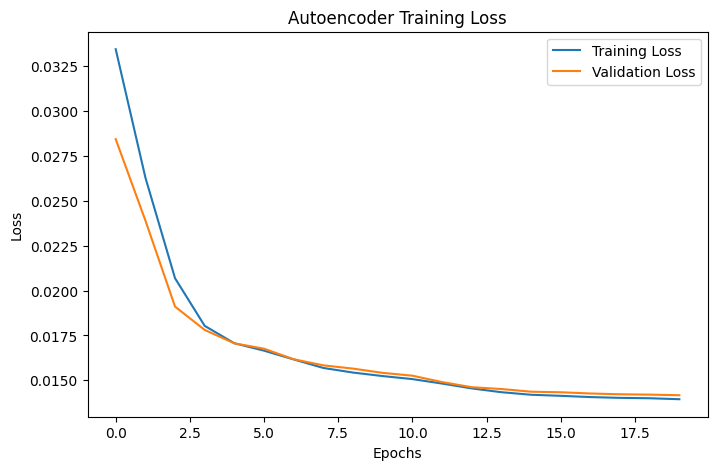

In [8]:
# =====================================================
# STEP 8: PLOT TRAINING LOSS
# =====================================================

plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Autoencoder Training Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()


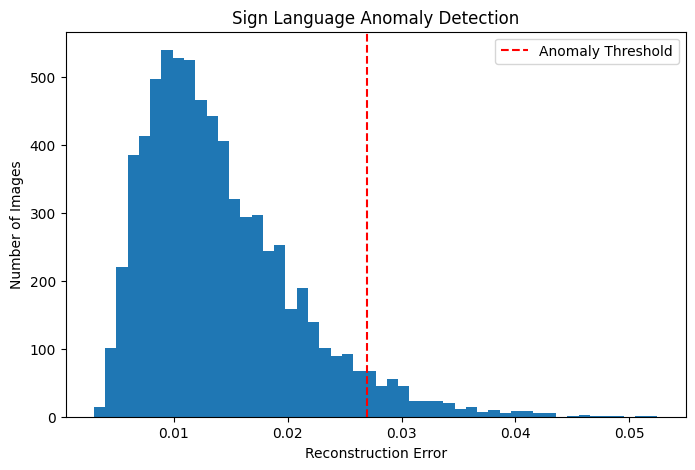

In [9]:
# =====================================================
# STEP 9: PLOT RECONSTRUCTION ERROR
# =====================================================

plt.figure(figsize=(8, 5))

plt.hist(reconstruction_error, bins=50)

plt.axvline(
    threshold,
    color='red',
    linestyle='--',
    label='Anomaly Threshold'
)

plt.title('Sign Language Anomaly Detection')
plt.xlabel('Reconstruction Error')
plt.ylabel('Number of Images')
plt.legend()
plt.show()


In [10]:
# =====================================================
# STEP 10: DISPLAY ANOMALY RESULTS
# =====================================================

print("\nAnomaly Detection Results:")

for i in range(min(10, len(y_pred))):

    if y_pred[i] == 1:
        print("Image", i, ": Anomaly Detected (Y)")
    else:
        print("Image", i, ": Normal")



Anomaly Detection Results:
Image 0 : Normal
Image 1 : Normal
Image 2 : Normal
Image 3 : Normal
Image 4 : Normal
Image 5 : Normal
Image 6 : Normal
Image 7 : Normal
Image 8 : Normal
Image 9 : Normal
